# Tối ưu Random Forest cho nhận dạng chữ số viết tay

Notebook trình bày bài toán, kiểm tra dữ liệu, đọc lịch sử tìm kiếm và demo mô hình.
Kết quả hiển thị lấy từ CSV/JSON do mã nguồn sinh ra. Notebook không tự chạy lại
180 trials khi bạn mở hoặc Run All.

**Câu hỏi:** với cùng 30 trials mỗi lần chạy, TPE và Random Search tìm được
cấu hình có Macro-F1 validation ra sao? Trong những cấu hình gần điểm tốt nhất,
cấu hình nào có kích thước nhỏ nhất?


In [1]:
from pathlib import Path
import sys, json
ROOT = Path.cwd().resolve()
if not (ROOT / 'src').exists():
    ROOT = ROOT.parent
if not (ROOT / 'src').exists():
    raise RuntimeError('Open this notebook inside the project folder.')
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display, Image
from src.common import load_config, make_data, make_model
OUTPUT = ROOT / 'results'
config = load_config(ROOT / 'configs/experiment.json')
config

{'dataset': 'sklearn_digits',
 'test_size': 0.2,
 'split_seed': 42,
 'cv_folds': 3,
 'cv_seed': 42,
 'model_seed': 123,
 'search_seeds': [11, 22, 33],
 'trials_per_method': 30,
 'tpe_startup_trials': 10,
 'epsilon': 0.005,
 'n_jobs': 1,
 'latency_repeats': 15,
 'search_space': {'n_estimators': {'low': 50, 'high': 200, 'step': 25},
  'max_depth': [5, 10, 15, 20, None],
  'min_samples_leaf': {'low': 1, 'high': 4},
  'max_features': ['sqrt', 'log2', 'half', 'all']}}

## Mô hình hóa bài toán

Biến quyết định `x = (n_estimators, max_depth, min_samples_leaf, max_features)`.
Miền khả thi lấy từ `configs/experiment.json`.

Hàm mục tiêu chính: `max mean(Macro-F1 trên 3 folds development)`.
Macro-F1 là trung bình F1 của 10 lớp, mỗi lớp có trọng số bằng nhau.
Ngân sách: 30 trials cho mỗi phương pháp và mỗi search seed, không pruning.

Quyết định triển khai: tối thiểu kích thước mô hình trong tập ứng viên có
`CV Macro-F1 >= CV tốt nhất - 0.005`. Đây là quy tắc epsilon định trước trên
**development**, không sử dụng điểm test. Epsilon 0.005 là 0.5 điểm phần trăm
F1 tuyệt đối, không phải kiểm định tương đương thống kê.


Dataset: (1797, 64) development: 1437 test: 360
Test overlap with development: 0


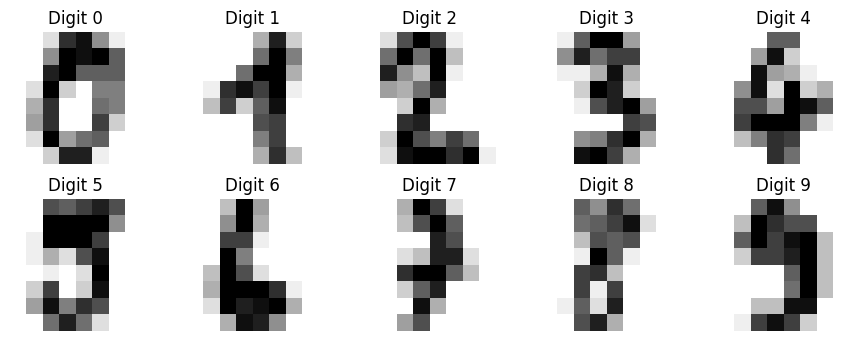

In [2]:
digits, development, test, folds = make_data(config)
print('Dataset:', digits.data.shape, 'development:', len(development), 'test:', len(test))
print('Test overlap with development:', len(set(development) & set(test)))
fig, axes = plt.subplots(2, 5, figsize=(9, 3.5))
for digit, ax in enumerate(axes.flat):
    idx = development[np.flatnonzero(digits.target[development] == digit)[0]]
    ax.imshow(digits.images[idx], cmap='gray_r', vmin=0, vmax=16)
    ax.set_title(f'Digit {digit}')
    ax.axis('off')
plt.tight_layout()
plt.show()

## Baseline và thuật toán tìm kiếm

Baseline là Random Forest với tham số học mặc định, chỉ cố định `random_state`
và `n_jobs=1`. Random Search lấy mẫu độc lập trong miền tìm kiếm. TPE dùng 10
trials đầu để khởi tạo ngẫu nhiên, sau đó dùng lịch sử đánh giá để mô hình hóa
nhóm cấu hình tốt và nhóm còn lại, ưu tiên vùng có triển vọng cho trial tiếp theo.

Các phương pháp dùng cùng split, folds, metric, miền tìm kiếm và ngân sách.
RF seed giữ nguyên 123. Ba search seed 11, 22, 33 đánh giá độ biến thiên của
quá trình tìm kiếm, không đo toàn bộ bất định do cách chia dữ liệu.


In [3]:
baseline = json.loads((OUTPUT / 'baseline.json').read_text(encoding='utf-8'))
print('Default parameters:', baseline['params'])
print('CV fold scores:', baseline['fold_scores'])
print('Default CV Macro-F1:', baseline['cv_f1'])
trials = pd.read_csv(OUTPUT / 'trials.csv')
display(trials.groupby(['method','seed']).agg(trials=('trial','count'), best_cv_f1=('cv_f1','max')))
display(trials.head())

Default parameters: {'n_estimators': 100, 'max_depth': None, 'min_samples_leaf': 1, 'max_features': 'sqrt'}
CV fold scores: [0.9685005713675003, 0.9707521635422068, 0.9725938131500316]
Default CV Macro-F1: 0.9706155160199129


trials  best_cv_f1
method  seed                    
default 123        1    0.970616
random  11        30    0.973429
        22        30    0.974848
        33        30    0.971929
tpe     11        30    0.969129
        22        30    0.974142
        33        30    0.973352

,method,seed,trial,cv_f1,cv_fold_std,cv_seconds,refit_seconds,feasible,model_bytes,total_nodes,batch_predict_ms_median,batch_predict_ms_p95,batch_samples,ms_per_sample,n_estimators,max_depth,min_samples_leaf,max_features,fold_scores,started_at_utc
0,default,123,-1,0.970616,0.002050,0.525591,0.206448,True,4975993,34234,5.1786,5.96623,256,0.020229,100,NaN,1,sqrt,"[0.9685005713675003, 0.9707521635422068, 0.972...",NaN
1,random,11,0,0.966316,0.002157,0.392167,0.142061,True,4179593,28773,3.9409,5.60668,256,0.015394,75,15.0,1,log2,"[0.9684362960889974, 0.9663859333919446, 0.964...",2026-10-13T03:33:36.727857+00:00
2,random,11,1,0.870758,0.039940,0.599973,0.302227,True,381225,2476,2.0911,2.52137,256,0.008168,50,5.0,1,all,"[0.8943142330168203, 0.824642158210873, 0.8933...",2026-10-13T03:33:37.362037+00:00
3,random,11,2,0.963616,0.014328,1.031317,0.504385,True,3405097,23314,4.5561,4.97579,256,0.017797,100,20.0,1,half,"[0.9749457594507396, 0.947510578394037, 0.9683...",2026-10-13T03:33:38.311257+00:00
4,random,11,3,0.962270,0.007501,0.641262,0.251748,True,4653449,31822,8.1066,9.79297,256,0.031666,150,15.0,4,log2,"[0.9604181154412874, 0.9558685026404365, 0.970...",2026-10-13T03:33:39.952355+00:00


## Chạy lại thực nghiệm

Toàn bộ pipeline nằm trong `run_experiment.py`. Lệnh:

```bash
python run_experiment.py --output results/reproduction-01
```

Mỗi lần chạy dùng một thư mục kết quả mới để giữ nguyên số liệu đã có.
Nếu thay config hoặc budget, kết quả đó thuộc một thực nghiệm khác. Chạy tất
cả cells dưới đây chỉ đọc và kiểm tra bộ kết quả đã lưu.


In [4]:
# Chỉ đặt True khi muốn chạy một thực nghiệm MỚI đầy đủ.
RUN_NEW_EXPERIMENT = False
if RUN_NEW_EXPERIMENT:
    from src.experiment import run_experiment
    from src.analysis import analyze
    from src.validation import validate_results
    new_output = ROOT / 'results' / 'reproduction-notebook'
    run_experiment(config, new_output)
    analyze(new_output)
    validate_results(new_output)

## Lịch sử tìm kiếm và độ ổn định
Dải màu thể hiện ±1 độ lệch chuẩn qua ba search seed. Đây không phải khoảng tin cậy.

,method,best_cv_f1_mean,best_cv_f1_std,cv_seconds_mean,cv_seconds_std,runs
0,random,0.973402,0.001460,48.751223,13.497284,3
1,tpe,0.972208,0.002695,40.465043,26.149328,3


,method,seed,best_cv_f1,search_cv_seconds,profiling_and_refit_seconds,trials
0,random,11,0.973429,56.397513,24.393937,30
1,random,22,0.974848,56.689343,23.949173,30
2,random,33,0.971929,33.166813,14.803925,30
3,tpe,11,0.969129,23.175204,10.338253,30
4,tpe,22,0.974142,27.672064,11.828824,30
5,tpe,33,0.973352,70.547859,28.260253,30


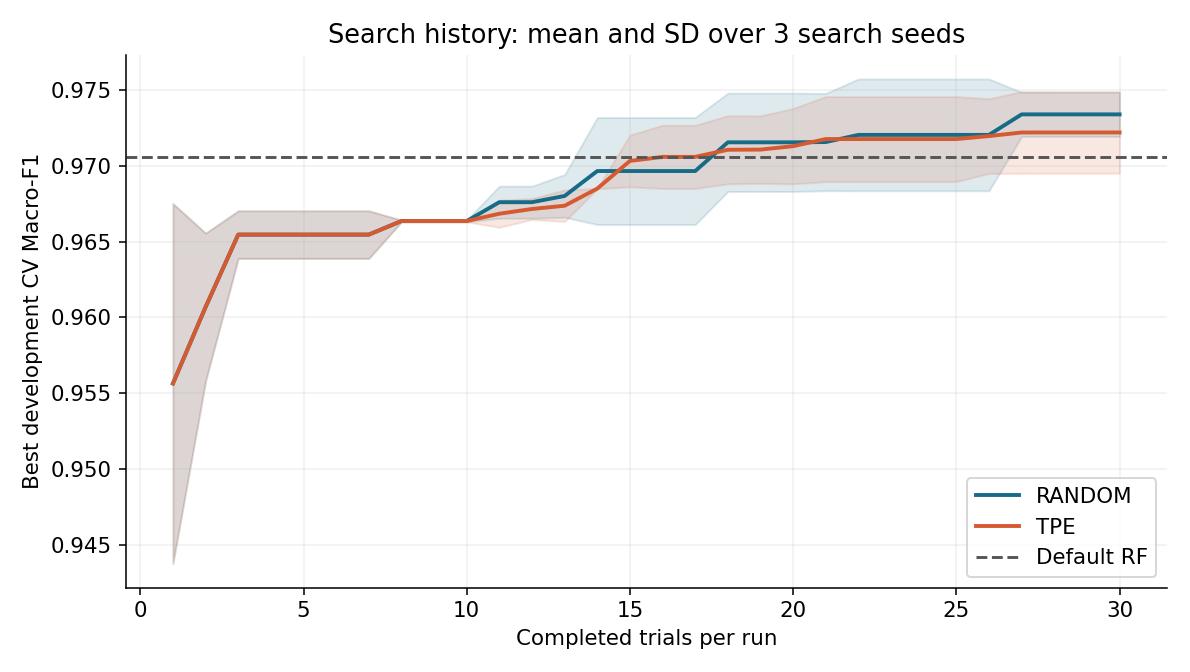

In [5]:
display(pd.read_csv(OUTPUT / 'search_summary.csv'))
display(pd.read_csv(OUTPUT / 'best_per_seed.csv'))
display(Image(filename=str(OUTPUT / 'figures/search_history.png')))

## Trade off chất lượng và kích thước

Đồ thị sử dụng **điểm CV**, đo kích thước joblib không nén theo MB thập phân.
Đường Pareto chỉ là biên của các cấu hình đã thử, không chứng minh tối ưu toàn cục.
Thời gian dự đoán đo trên batch development cố định 256 ảnh, 3 lần warmup và
15 lần lặp. `ms_per_sample` là thời gian batch chia số mẫu, không phải latency
của một request riêng lẻ. Thời gian có thể thay đổi theo máy và tải hệ thống.


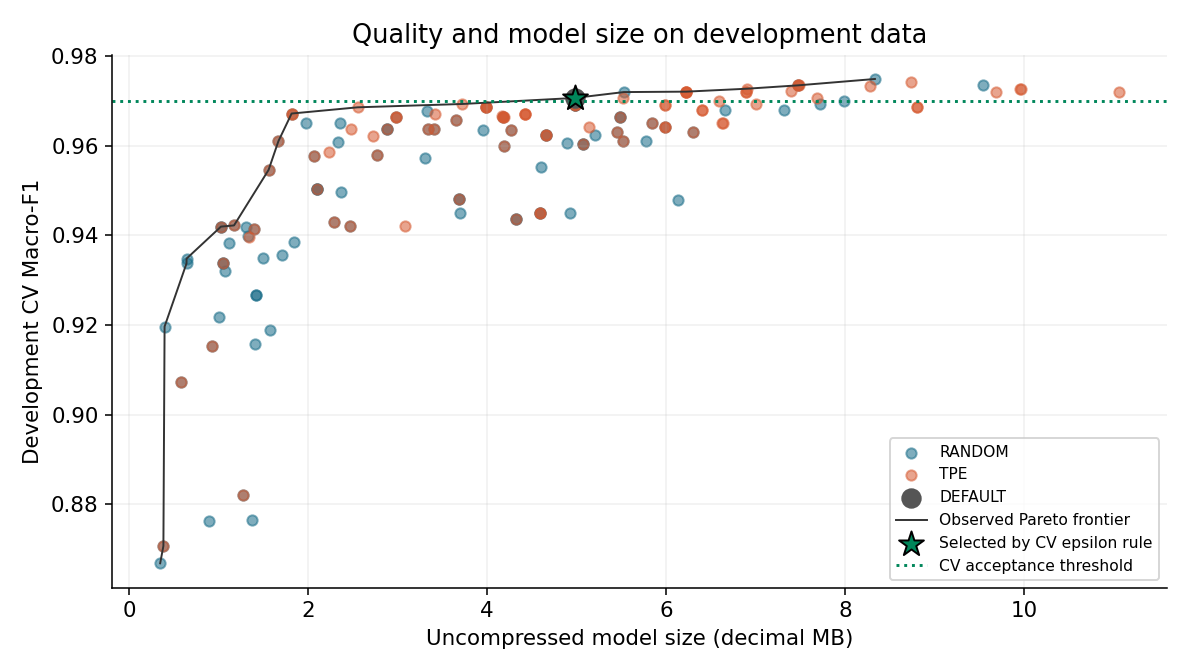

Best CV score: 0.9748483763754859
Minimum acceptable CV score: 0.9698483763754859
Chosen parameters: {'n_estimators': 100, 'max_depth': None, 'min_samples_leaf': 1, 'max_features': 'sqrt'}


,epsilon,selected_cv_f1,cv_gap,model_mb,method,seed,trial
0,0.0000,0.974848,0.000000,8.332873,random,22,21
1,0.0025,0.972676,0.002172,6.900521,tpe,33,15
2,0.0050,0.970616,0.004233,4.975993,default,123,-1
3,0.0100,0.967147,0.007702,1.814105,tpe,11,20
4,0.0200,0.960991,0.013858,1.666569,random,33,28


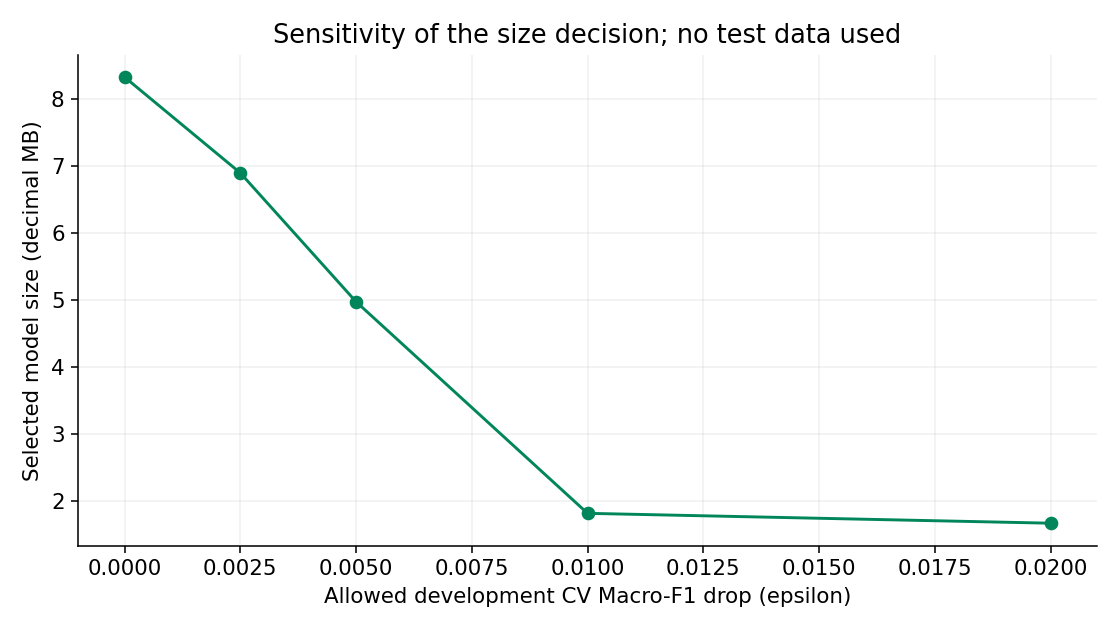

In [6]:
display(Image(filename=str(OUTPUT / 'figures/quality_size_tradeoff.png')))
decision = json.loads((OUTPUT / 'selection.json').read_text(encoding='utf-8'))
print('Best CV score:', decision['best_cv_f1'])
print('Minimum acceptable CV score:', decision['minimum_acceptable_cv_f1'])
print('Chosen parameters:', decision['selected_params'])
display(pd.read_csv(OUTPUT / 'epsilon_sensitivity.csv'))
display(Image(filename=str(OUTPUT / 'figures/epsilon_sensitivity.png')))

## Đánh giá test sau khi chốt cấu hình

Mặc định, cấu hình tốt nhất của Random Search, cấu hình tốt nhất của TPE và
cấu hình nhỏ được chọn là bốn đại diện đã định trước. Mã nguồn chốt các đại
diện bằng CV rồi mới đánh giá test. Không đổi cấu hình dựa trên bảng test.
Tất cả mô hình huấn luyện trên development 80%, không refit lên test.


,label,cv_f1,test_f1,test_accuracy,source_method,source_seed,source_trial,model_mb,total_nodes,development_batch_ms
0,default,0.970616,0.971787,0.972222,default,123,-1,4.975993,34234,5.1786
1,random,0.974848,0.974634,0.975000,random,22,21,8.332873,57293,9.2943
2,tpe,0.974142,0.971787,0.972222,tpe,22,26,8.730601,60055,9.0074
3,selected,0.970616,0.971787,0.972222,default,123,-1,4.975993,34234,5.1786


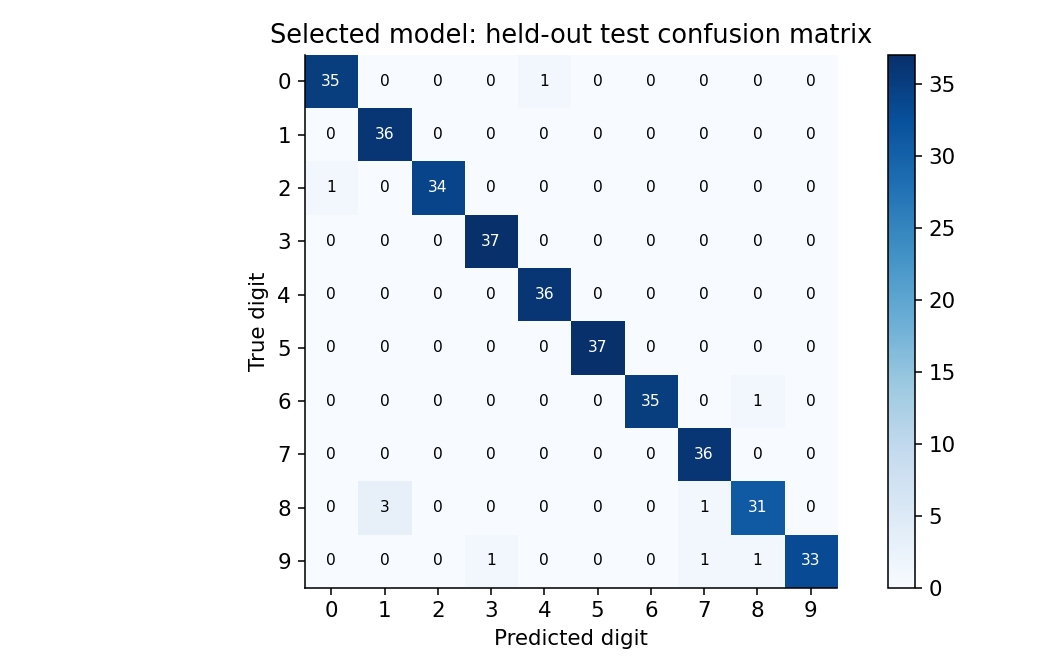

C:\Users\lequy\AppData\Local\Temp\ipykernel_2764\3699437843.py:3: FutureWarning: The behavior of 'to_datetime' with 'unit' when parsing strings is deprecated. In a future version, strings will be parsed as datetime strings, matching the behavior without a 'unit'. To retain the old behavior, explicitly cast ints or floats to numeric type before calling to_datetime.
  display(pd.read_json(OUTPUT / 'classification_selected.json').T)
C:\Users\lequy\AppData\Local\Temp\ipykernel_2764\3699437843.py:3: FutureWarning: The behavior of 'to_datetime' with 'unit' when parsing strings is deprecated. In a future version, strings will be parsed as datetime strings, matching the behavior without a 'unit'. To retain the old behavior, explicitly cast ints or floats to numeric type before calling to_datetime.
  display(pd.read_json(OUTPUT / 'classification_selected.json').T)
C:\Users\lequy\AppData\Local\Temp\ipykernel_2764\3699437843.py:3: FutureWarning: The behavior of 'to_datetime' with 'unit' when pars

,precision,recall,f1-score,support
0,0.972222,0.972222,0.972222,36.000000
1,0.923077,1.000000,0.960000,36.000000
2,1.000000,0.971429,0.985507,35.000000
3,0.973684,1.000000,0.986667,37.000000
4,0.972973,1.000000,0.986301,36.000000
5,1.000000,1.000000,1.000000,37.000000
6,1.000000,0.972222,0.985915,36.000000
7,0.947368,1.000000,0.972973,36.000000
8,0.939394,0.885714,0.911765,35.000000
9,1.000000,0.916667,0.956522,36.000000


{'selected_test_f1': 0.9717872416072222,
 'selected_test_accuracy': 0.9722222222222222,
 'selected_model_mb': 4.975993,
 'size_reduction_vs_default_percent': 0.0,
 'cv_gap_to_best': 0.0042328603555731315,
 'search_seed_summary': [{'method': 'random',
   'best_cv_f1_mean': 0.9734021920072121,
   'best_cv_f1_std': 0.0014596830291535902,
   'cv_seconds_mean': 48.7512231337217,
   'cv_seconds_std': 13.497283819087043,
   'runs': 3},
  {'method': 'tpe',
   'best_cv_f1_mean': 0.9722079420079858,
   'best_cv_f1_std': 0.002695465221800807,
   'cv_seconds_mean': 40.46504253304253,
   'cv_seconds_std': 26.14932756957182,
   'runs': 3}]}

In [7]:
display(pd.read_csv(OUTPUT / 'final_metrics.csv'))
display(Image(filename=str(OUTPUT / 'figures/confusion_matrix.png')))
display(pd.read_json(OUTPUT / 'classification_selected.json').T)
key_results = json.loads((OUTPUT / 'key_results.json').read_text(encoding='utf-8'))
key_results

## Demo mô hình đã lưu
Đây là demo trên mẫu có sẵn trong dataset. Khả năng xử lý ảnh điện thoại hoặc chữ viết tay ngoài dataset chưa được kiểm chứng.

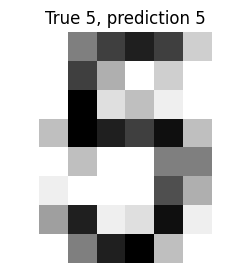

Parameters: {'n_estimators': 100, 'max_depth': None, 'min_samples_leaf': 1, 'max_features': 'sqrt'}


In [8]:
import joblib
model = joblib.load(OUTPUT / 'models/selected.joblib')
example = test[0]
predicted = int(model.predict(digits.data[[example]])[0])
plt.figure(figsize=(3,3))
plt.imshow(digits.images[example], cmap='gray_r', vmin=0, vmax=16)
plt.title(f'True {digits.target[example]}, prediction {predicted}')
plt.axis('off')
plt.show()
print('Parameters:', {k:model.get_params()[k] for k in decision['selected_params']})

## Kiểm chứng và giới hạn

Kiểm chứng kiểm tra split, ngân sách, miền khả thi, quy tắc chọn mô hình,
khả năng tái tạo dự đoán từ model và tính lại metric từ CSV.
Chỉ có một dataset, một holdout và ba search seed. Chênh lệch F1 nhỏ có thể
do mẫu hữu hạn. Folds có liên quan vì cùng development set. Ba search seed
không đủ để kết luận một thuật toán luôn tốt hơn. Bộ dữ liệu vốn là subset
test của UCI do sklearn đóng gói, nhưng trong nghiên cứu này được chia lại
độc lập và tên gọi đó không làm thay đổi protocol đang dùng.


In [9]:
from src.validation import validate_results
checks = validate_results(OUTPUT)
print('Number of passed checks:', len(checks))
manifest = json.loads((OUTPUT / 'run_manifest.json').read_text(encoding='utf-8'))
print('Actual runtime in seconds:', round(manifest['runtime_seconds'], 2))
print('Library versions:', manifest['versions'])

C:\Users\lequy\OneDrive\Desktop\Bài Tập Lớn cô Anh\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


PASS: 401 result integrity checks


Number of passed checks: 401
Actual runtime in seconds: 431.21
Library versions: {'numpy': '2.2.2', 'pandas': '2.2.3', 'scikit-learn': '1.8.0', 'optuna': '5.0.0', 'matplotlib': '3.10.0', 'joblib': '1.5.3'}


## Nguồn và công cụ hỗ trợ

- Dataset: https://scikit-learn.org/stable/modules/generated/sklearn.datasets.load_digits.html
- UCI: https://archive.ics.uci.edu/dataset/80/optical+recognition+of+handwritten+digits
- Random Forest: https://scikit-learn.org/stable/modules/generated/sklearn.ensemble.RandomForestClassifier.html
- Optuna: https://optuna.readthedocs.io/en/stable/reference/samplers/index.html

Codex hỗ trợ tổ chức mã nguồn, viết notebook và kiểm tra pipeline. Kết quả
đến từ thực nghiệm Python đã chạy. Người thực hiện cần tự chạy lại và giải
thích được biến quyết định, objective, protocol, trade off và quyết định cuối.
